# Mini Project 16 — Running Project Keyword Spotting Embedded

**Anggota Kelompok:**
1. Christama Ezra Yudianto (245150307111009)
2. Abdillah Fatah Suryanto (245150300111008)
3. Ivang Arfandia (245150307111003)
4. Jahzeel Erason Nicodemus (245150300111002)

Notebook ini dibangkitkan dari `mini_project_16.py` (bagian wajib) dan `features/mp16_extension_system_integration.py` (FITUR TAMBAHAN) lalu dieksekusi dari root folder mini project.

# Mini Project 16 — Integrasi End-to-End dan Acceptance Test Proyek Final
Artefak beku MP15 dijalankan sebagai **satu sistem** (WAV → filter MP6 → preprocessing MP7 → feature MP8 →
seleksi MP10 → model INT8 MP15 → aksi), konsistensinya diverifikasi terhadap prediksi MP13, latency diukur,
acceptance report dibuat, lalu status serial ditutup menjadi `project_complete`.

Adaptasi terhadap kode buku:
* **Gate family-aware**: buku mewajibkan `classical_svm_int8`; MP15 running project ini (dengan policy buku) memilih
  `classical_tree_int8`, sehingga gate menerima model klasik INT8 apa pun yang tercantum di manifest MP15 dan
  `predict_int8` memilih jalur linear/tree sesuai `kind` di paket `mp15_classical_int8.npz`.
  Kunci metrik MP15 `svm_int8` → `classical_int8` (dibaca dengan fallback).
* `LIVE_MIC` dibaca dari environment `MP16_LIVE_MIC=1` (default False → replay acceptance) agar notebook tetap non-interaktif.
  Live demo dijalankan di terminal: `set MP16_LIVE_MIC=1` lalu `python mini_project_16.py`.
* Aksi (nyala=ON, mati=OFF, naik=level+, turun=level−) dengan batas 0..10 dan fail-safe ditambahkan di bagian replay (Langkah 5).

In [1]:
# Anggota Kelompok :
# 1. Christama Ezra Yudianto    (245150307111009)
# 2. Abdillah Fatah Suryanto    (245150300111008)
# 3. Ivang Arfandia             (245150307111003)
# 4. Jahzeel Erason Nicodemus   (245150300111002)
from pathlib import Path
import csv, json, time, hashlib, os
import numpy as np
import matplotlib
if "__file__" in globals():
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import lfilter
from scipy.fft import dct

ROOT = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
LIVE_MIC = os.environ.get('MP16_LIVE_MIC', '0') == '1'      # True pada Raspberry Pi/PC dengan mikrofon
LIVE_DURATION_S = 1.2
SEED = 2026
np.random.seed(SEED)


def save_json(path, obj):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, indent=2), encoding='utf-8')


def sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(65536), b''):
            h.update(block)
    return h.hexdigest()

## 1. Gate serial MP15 → MP16

In [2]:
status_path = ROOT/'project_status.json'
status = json.loads(status_path.read_text(encoding='utf-8'))
if status.get('status') not in ('ready_for_mp16', 'project_complete'):
    raise RuntimeError(f"Status harus ready_for_mp16, ditemukan {status.get('status')!r}")

manifest = json.loads((ROOT/'deployment/mp15_manifest.json').read_text(encoding='utf-8'))
dep_cfg = json.loads((ROOT/'config/deployment_config.json').read_text(encoding='utf-8'))
rt_cfg = json.loads((ROOT/'config/realtime_architecture_config.json').read_text(encoding='utf-8'))
proj_cfg = json.loads((ROOT/'config/project_config.json').read_text(encoding='utf-8'))
pre_cfg = json.loads((ROOT/'config/preprocessing_config.json').read_text(encoding='utf-8'))
feat_cfg = json.loads((ROOT/'config/feature_config.json').read_text(encoding='utf-8'))
mp13 = json.loads((ROOT/'results/metrics/mp13_final_test_metrics.json').read_text(encoding='utf-8'))
mp14 = json.loads((ROOT/'results/metrics/mp14_realtime_metrics.json').read_text(encoding='utf-8'))
mp15 = json.loads((ROOT/'results/metrics/mp15_deployment_metrics.json').read_text(encoding='utf-8'))
split = json.loads((ROOT/'splits/mp09_split.json').read_text(encoding='utf-8'))
mp15_cls = mp15.get('classical_int8', mp15.get('svm_int8'))

if manifest['selected_model'] != dep_cfg['selected_deployment_model']:
    raise RuntimeError('Manifest MP15 dan deployment_config tidak konsisten.')
if dep_cfg.get('post_test_tuning_performed'):
    raise RuntimeError('Post-test tuning terdeteksi. Integrasi dihentikan.')
if not (manifest['selected_model'].startswith('classical_') and manifest['selected_model'].endswith('_int8')):
    raise RuntimeError('Script MP16 ini memakai jalur utama model klasik INT8 yang dipilih MP15.')
print('Gate OK | selected model =', manifest['selected_model'], '| family =', manifest.get('classical_family'))

Gate OK | selected model = classical_tree_int8 | family = tree


## 2. Front-end beku + model klasik INT8

In [3]:
FS = int(manifest['sample_rate_hz'])
LABELS = list(manifest['classes'])
filter_npz = np.load(ROOT/'features/intermediate/mp06_filter_final.npz', allow_pickle=True)
B = np.asarray(filter_npz['b'], dtype=float)
A = np.asarray(filter_npz['a'], dtype=float)
N = int(pre_cfg['frame_length_samples'])
H = int(pre_cfg['hop_length_samples'])
TARGET_PEAK = float(pre_cfg['normalization']['target_peak'])
PREEMPH = float(pre_cfg['pre_emphasis_alpha'])
N_MELS = int(feat_cfg['mel']['n_mels'])
N_MFCC = int(feat_cfg['mfcc']['n_mfcc'])
FMIN = float(feat_cfg['mel']['fmin_hz'])
FMAX = float(feat_cfg['mel']['fmax_hz'])

pkg = np.load(ROOT/'models/mp15_classical_int8.npz', allow_pickle=True)
KIND = str(pkg['kind']) if 'kind' in pkg else 'linear'
SEL = pkg['selected_indices'].astype(int)
MU = pkg['selected_mean'].astype(float)
SIG = pkg['selected_scale'].astype(float)
XQ_SCALE = float(pkg['input_quant_scale'][0])
CLASSES = pkg['classes'].astype(str).tolist()
assert CLASSES == LABELS
if KIND == 'linear':
    WQ = pkg['weight_q'].astype(np.int8)
    W_SCALE = pkg['weight_scales'].astype(float)
    BIAS = pkg['bias'].astype(float)
else:
    T_FEAT = pkg['tree_feature'].astype(int); T_THR = pkg['tree_threshold_q'].astype(int)
    T_LEFT = pkg['tree_left'].astype(int); T_RIGHT = pkg['tree_right'].astype(int); T_LEAF = pkg['tree_leaf_class'].astype(int)
print('Paket INT8:', KIND, '| input scale', XQ_SCALE, '| SHA-256 header =', sha256(ROOT/'firmware/mp15_classical_model_int8.h')[:16], '...')


def hz_to_mel(f): return 2595*np.log10(1+np.asarray(f)/700.0)
def mel_to_hz(m): return 700*(10**(np.asarray(m)/2595.0)-1)


def melbank(n_fft):
    m = np.linspace(hz_to_mel(FMIN), hz_to_mel(FMAX), N_MELS+2)
    hz = mel_to_hz(m); bins = np.floor((n_fft+1)*hz/FS).astype(int)
    fb = np.zeros((N_MELS, n_fft//2+1))
    for i in range(1, N_MELS+1):
        l, c, r = bins[i-1], bins[i], bins[i+1]; c = max(c, l+1); r = max(r, c+1)
        for k in range(l, min(c, fb.shape[1])): fb[i-1, k] = (k-l)/(c-l)
        for k in range(c, min(r, fb.shape[1])): fb[i-1, k] = (r-k)/(r-c)
    return fb


FB = melbank(N)
FREQ = np.fft.rfftfreq(N, 1/FS)


def read_float(path):
    fs, y = wavfile.read(path)
    if fs != FS: raise RuntimeError(f'{path}: sample rate {fs}, seharusnya {FS}')
    if y.ndim > 1: y = y.mean(axis=1)
    if np.issubdtype(y.dtype, np.integer): y = y.astype(np.float64)/np.iinfo(y.dtype).max
    else: y = y.astype(np.float64)
    return y


def preprocess(y):
    y = lfilter(B, A, y)
    y = y-np.mean(y)
    y = y*(TARGET_PEAK/(np.max(np.abs(y))+1e-12))
    if len(y) < N: y = np.pad(y, (0, N-len(y)))
    starts = np.arange(0, len(y)-N+1, H)
    raw = np.array([y[s:s+N] for s in starts])
    rms = np.sqrt(np.mean(raw**2, axis=1)+1e-12)
    thr = float(pre_cfg['vad']['relative_factor'])*np.max(rms)
    active = np.where(rms >= thr)[0]
    if len(active):
        margin = int(pre_cfg['vad'].get('margin_frames', 2))
        i0 = max(0, int(active[0])-margin); i1 = min(len(raw)-1, int(active[-1])+margin)
        y = y[starts[i0]:min(len(y), starts[i1]+N)]
    if len(y) < N: y = np.pad(y, (0, N-len(y)))
    starts = np.arange(0, len(y)-N+1, H)
    fr = np.array([y[s:s+N] for s in starts])
    fr = np.concatenate([fr[:, :1], fr[:, 1:]-PREEMPH*fr[:, :-1]], axis=1)
    return fr*np.hamming(N)[None, :]


def pitch_one(frame):
    x = frame-np.mean(frame); ac = np.correlate(x, x, mode='full')[len(x)-1:]
    if ac[0] <= 1e-12: return 0.0
    ac = ac/(ac[0]+1e-12)
    lo = max(1, int(FS/feat_cfg['pitch']['max_hz'])); hi = min(len(ac)-1, int(FS/feat_cfg['pitch']['min_hz']))
    if hi <= lo: return 0.0
    lag = int(np.argmax(ac[lo:hi+1])+lo); conf = float(ac[lag])
    if conf < float(feat_cfg['pitch']['confidence_threshold']): return 0.0
    return float(FS/lag)


def extract39(y):
    frames = preprocess(y)
    rms = np.sqrt(np.mean(frames**2, axis=1)+1e-12)
    zcr = np.mean(np.abs(np.diff(np.signbit(frames), axis=1)), axis=1)
    spec = np.abs(np.fft.rfft(frames, axis=1))+1e-12; power = spec**2
    den = np.sum(power, axis=1)+1e-12
    centroid = np.sum(power*FREQ[None, :], axis=1)/den
    bw = np.sqrt(np.sum(power*(FREQ[None, :]-centroid[:, None])**2, axis=1)/den)
    cum = np.cumsum(power, axis=1); total = cum[:, -1]
    roll = np.array([FREQ[min(np.searchsorted(cum[i], .85*total[i]), len(FREQ)-1)] for i in range(len(frames))])
    pitch = np.array([pitch_one(f) for f in frames]); voiced = pitch > 0
    mel = np.maximum(power@FB.T, 1e-12); logmel = np.log(mel)
    mfcc = dct(logmel, type=2, axis=1, norm='ortho')[:, :N_MFCC]
    vals = []
    for j in range(N_MFCC): vals += [float(np.mean(mfcc[:, j])), float(np.std(mfcc[:, j]))]
    for a in [rms, zcr, centroid, bw, roll]: vals += [float(np.mean(a)), float(np.std(a))]
    pv = pitch[voiced]
    vals += [float(np.mean(pv)) if len(pv) else 0.0, float(np.std(pv)) if len(pv) else 0.0, float(np.mean(voiced))]
    v = np.asarray(vals, dtype=np.float32)
    if v.shape != (39,) or not np.isfinite(v).all(): raise RuntimeError('Feature vector MP16 tidak valid.')
    return v


def predict_int8(v39):
    z = (v39[SEL]-MU)/SIG
    zq = np.clip(np.round(z/XQ_SCALE), -127, 127).astype(np.int8)
    if KIND == 'linear':
        acc = WQ.astype(np.int32)@zq.astype(np.int32)
        scores = acc.astype(float)*(W_SCALE*XQ_SCALE)+BIAS
        k = int(np.argmax(scores))
        return CLASSES[k], scores
    n = 0; path = []
    while T_FEAT[n] >= 0:
        path.append(n); n = T_LEFT[n] if int(zq[T_FEAT[n]]) <= T_THR[n] else T_RIGHT[n]
    scores = np.zeros(len(CLASSES)); scores[T_LEAF[n]] = 1.0      # tree: one-hot leaf (tanpa skor kontinu)
    return CLASSES[int(T_LEAF[n])], scores

Paket INT8: tree | input scale 0.015133383683860302 | SHA-256 header = 26c2bf2db71636f1 ...


## 3. Replay acceptance pada WAV test beku (+ aksi console dengan batas & fail-safe)

In [4]:
meta = {}
with (ROOT/'data/metadata/mp09_metadata.csv').open(encoding='utf-8') as f:
    for r in csv.DictReader(f): meta[r['sample_id']] = r
mp13_pred = {}
with (ROOT/'results/predictions/mp13_test_predictions.csv').open(encoding='utf-8') as f:
    for r in csv.DictReader(f): mp13_pred[r['sample_id']] = r

LEVEL_MIN, LEVEL_MAX = 0, 10
device = {'power': False, 'level': 5}


def apply_action(cmd, dev):
    """nyala=ON, mati=OFF, naik=level+, turun=level-. Level hanya berubah saat ON; batas 0..10 (fail-safe: clamp)."""
    if cmd == 'nyala': dev['power'] = True
    elif cmd == 'mati': dev['power'] = False
    elif cmd == 'naik' and dev['power']: dev['level'] = min(LEVEL_MAX, dev['level']+1)
    elif cmd == 'turun' and dev['power']: dev['level'] = max(LEVEL_MIN, dev['level']-1)
    return dict(dev)


rows = []; feature_ms = []; infer_ms = []; total_ms = []
for sid in split['test_ids']:
    wav_path = ROOT/meta[sid]['path']
    y = read_float(wav_path)
    t0 = time.perf_counter_ns(); v = extract39(y); t1 = time.perf_counter_ns(); pred, scores = predict_int8(v); t2 = time.perf_counter_ns()
    fm = (t1-t0)/1e6; im = (t2-t1)/1e6; tm = (t2-t0)/1e6
    expected = meta[sid]['label']; frozen = mp13_pred[sid]['classical_prediction']
    st = apply_action(pred, device)
    rows.append({'sample_id': sid, 'expected': expected, 'mp13_classical_pred': frozen, 'mp16_int8_pred': pred, 'correct': pred == expected,
                 'agreement_mp13': pred == frozen, 'feature_ms': fm, 'inference_ms': im, 'total_ms': tm, 'audio_duration_ms': len(y)/FS*1000,
                 'action_power': st['power'], 'action_level': st['level']})
    feature_ms.append(fm); infer_ms.append(im); total_ms.append(tm)
    print(f"  {sid}: expected={expected:6s} mp13={frozen:6s} mp16={pred:6s} | {tm:6.2f} ms | aksi -> power={'ON' if st['power'] else 'OFF'} level={st['level']}")

  nyala_b06: expected=nyala  mp13=nyala  mp16=nyala  |   4.41 ms | aksi -> power=ON level=5
  mati_b06: expected=mati   mp13=mati   mp16=mati   |   2.99 ms | aksi -> power=OFF level=5
  naik_b06: expected=naik   mp13=naik   mp16=naik   |   2.56 ms | aksi -> power=OFF level=5
  turun_b06: expected=turun  mp13=turun  mp16=turun  |   3.33 ms | aksi -> power=OFF level=5


## 4. Live microphone demo (opsional, `MP16_LIVE_MIC=1`)

In [5]:
live_rows = []
if LIVE_MIC:
    import sounddevice as sd
    for expected in ['nyala', 'mati', 'naik', 'turun']:
        input(f'Ucapkan "{expected}" lalu tekan ENTER... ')
        y = sd.rec(int(LIVE_DURATION_S*FS), samplerate=FS, channels=1, dtype='float32'); sd.wait(); y = y[:, 0].astype(float)
        t0 = time.perf_counter_ns(); v = extract39(y); pred, scores = predict_int8(v); elapsed = (time.perf_counter_ns()-t0)/1e6
        live_rows.append({'expected': expected, 'predicted': pred, 'correct': pred == expected, 'pipeline_ms': elapsed})
        print(f'  {expected} -> {pred} ({elapsed:.2f} ms)')
else:
    print('LIVE_MIC=False -> replay acceptance saja. Untuk live demo: set MP16_LIVE_MIC=1 lalu jalankan skrip ini di terminal.')

LIVE_MIC=False -> replay acceptance saja. Untuk live demo: set MP16_LIVE_MIC=1 lalu jalankan skrip ini di terminal.


## 5. Acceptance metrics dan paket final

In [6]:
replay_accuracy = float(np.mean([r['correct'] for r in rows]))
agreement = float(np.mean([r['agreement_mp13'] for r in rows]))
rtf_p95 = float(np.percentile(total_ms, 95)/(LIVE_DURATION_S*1000))
stride_ms = float(rt_cfg['inference_stride_ms'])

checks = {
    'serial_gate_ready_for_mp16': True,
    'selected_model_matches_manifest': True,
    'post_test_tuning_false': not dep_cfg.get('post_test_tuning_performed', False),
    'mp15_numeric_agreement_test_ge_095': float(mp15_cls['agreement_test_vs_float']) >= 0.95,
    'mp14_overflow_is_0': int(mp14['overflow_count']) == 0,
    'replay_agreement_not_worse_than_mp15': agreement+1e-9 >= float(mp15_cls['agreement_test_vs_float']),
    'replay_features_are_finite': True,
    'p95_pipeline_faster_than_audio_duration': rtf_p95 < 1.0,
}
# Live microphone is informative, not a hard gate because acoustics and hardware vary.
all_required_pass = all(checks.values())

metrics = {
    'selected_model': manifest['selected_model'],
    'target_profile': dep_cfg['primary_target_profile'],
    'n_replay_samples': len(rows),
    'replay_accuracy': replay_accuracy,
    'replay_agreement_with_mp13': agreement,
    'feature_latency_ms': {'mean': float(np.mean(feature_ms)), 'p95': float(np.percentile(feature_ms, 95))},
    'inference_latency_ms': {'mean': float(np.mean(infer_ms)), 'p95': float(np.percentile(infer_ms, 95))},
    'pipeline_latency_ms': {'mean': float(np.mean(total_ms)), 'p95': float(np.percentile(total_ms, 95))},
    'pipeline_rtf_p95': rtf_p95,
    'realtime_stride_ms': stride_ms,
    'mp14_overflow_count': int(mp14['overflow_count']),
    'mp15_payload_bytes': int(mp15_cls['payload_bytes_estimate']),
    'live_microphone_enabled': LIVE_MIC,
    'live_demo': live_rows,
    'acceptance_checks': checks,
    'required_acceptance_pass': all_required_pass,
    'benchmark_platform': 'host PC (Windows, Python reference) - BUKAN angka ESP32/Raspberry Pi',
    'scientific_note': 'Replay test verifies end-to-end implementation consistency; it is not a new independent generalization estimate.'
}

out_pred = ROOT/'results/predictions/mp16_end_to_end_predictions.csv'; out_pred.parent.mkdir(parents=True, exist_ok=True)
with out_pred.open('w', newline='', encoding='utf-8') as f:
    fields = list(rows[0].keys()); w = csv.DictWriter(f, fieldnames=fields); w.writeheader(); w.writerows(rows)
save_json(ROOT/'results/metrics/mp16_acceptance_metrics.json', metrics)

syscfg = {
    'project': 'four_command_keyword_spotting_embedded',
    'classes': LABELS,
    'sample_rate_hz': FS,
    'input': 'mono_PCM16_or_float_equivalent',
    'dma_block_samples': int(manifest['dma_block_samples']),
    'frame_samples': int(manifest['feature_frame_samples']),
    'hop_samples': int(manifest['feature_hop_samples']),
    'inference_stride_frames': int(manifest['inference_stride_frames']),
    'selected_model': manifest['selected_model'],
    'selected_features': manifest['selected_feature_names'],
    'decision_map': {'nyala': 'LED/relay ON', 'mati': 'LED/relay OFF', 'naik': 'increase level', 'turun': 'decrease level'},
    'level_bounds': [LEVEL_MIN, LEVEL_MAX],
    'logging_fields': ['timestamp', 'predicted_class', 'score', 'pipeline_latency_ms', 'overflow_count'],
    'live_python_target': 'Raspberry Pi / PC Linux',
    'esp32_package': 'firmware/mp15_classical_model_int8.h',
    'no_post_test_tuning': True,
}
save_json(ROOT/'config/system_integration_config.json', syscfg)

# MCU constants and simple action mapping.
fw = ROOT/'firmware/mp16_project_config.h'; fw.parent.mkdir(parents=True, exist_ok=True)
fw.write_text(f'''// Generated by Mini Project 16
#pragma once
#define MP16_SAMPLE_RATE {FS}
#define MP16_DMA_BLOCK {manifest['dma_block_samples']}
#define MP16_FRAME_SAMPLES {manifest['feature_frame_samples']}
#define MP16_HOP_SAMPLES {manifest['feature_hop_samples']}
#define MP16_INFERENCE_STRIDE_FRAMES {manifest['inference_stride_frames']}
#define MP16_N_CLASSES {len(LABELS)}
#define MP16_LEVEL_MIN {LEVEL_MIN}
#define MP16_LEVEL_MAX {LEVEL_MAX}
// Class order: {', '.join(LABELS)}
''', encoding='utf-8')

final_manifest = {
    'project_complete': all_required_pass,
    'selected_model': manifest['selected_model'],
    'primary_runtime': 'Raspberry Pi/Python reference or ESP32/C++ port using frozen header',
    'model_package': 'models/mp15_classical_int8.npz',
    'model_c_header': 'firmware/mp15_classical_model_int8.h',
    'model_c_header_sha256': sha256(ROOT/'firmware/mp15_classical_model_int8.h'),
    'project_c_header': 'firmware/mp16_project_config.h',
    'system_config': 'config/system_integration_config.json',
    'acceptance_metrics': 'results/metrics/mp16_acceptance_metrics.json',
    'prediction_audit': 'results/predictions/mp16_end_to_end_predictions.csv',
    'frozen_test_metrics': 'results/metrics/mp13_final_test_metrics.json',
    'deployment_metrics': 'results/metrics/mp15_deployment_metrics.json',
    'source': ['mini_project_16.py', 'features/kws_frontend.py'],
    'post_test_tuning_performed': False,
}
save_json(ROOT/'deployment/mp16_final_project_manifest.json', final_manifest)

## 6. Visualisasi

In [7]:
figdir = ROOT/'results/figures'; figdir.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(7.2, 4.0))
ax.bar(['feature', 'inference', 'total'], [np.mean(feature_ms), np.mean(infer_ms), np.mean(total_ms)])
ax.set_ylabel('mean latency (ms)'); ax.set_title('MP16 end-to-end reference latency'); ax.grid(axis='y', alpha=.2)
fig.tight_layout(); fig.savefig(figdir/'mp16_latency_breakdown.png', dpi=160); plt.close(fig)

fig, ax = plt.subplots(figsize=(7.2, 4.0))
labels = list(checks.keys()); vals = [1 if checks[k] else 0 for k in labels]
ax.barh(range(len(labels)), vals, color=['C2' if v else 'C3' for v in vals]); ax.set_yticks(range(len(labels))); ax.set_yticklabels([x.replace('_', ' ') for x in labels], fontsize=7)
ax.set_xlim(0, 1.05); ax.set_xlabel('PASS = 1'); ax.set_title('MP16 acceptance checklist'); ax.grid(axis='x', alpha=.2)
fig.tight_layout(); fig.savefig(figdir/'mp16_acceptance_summary.png', dpi=160); plt.close(fig)

fig, ax = plt.subplots(figsize=(7.4, 4.0))
x = np.arange(len(rows)); ax.plot(x, [r['total_ms'] for r in rows], marker='o', label='pipeline')
ax.axhline(LIVE_DURATION_S*1000, ls='--', label='audio duration'); ax.set_xticks(x); ax.set_xticklabels([r['sample_id'] for r in rows], rotation=25, ha='right', fontsize=8)
ax.set_ylabel('ms'); ax.set_yscale('log'); ax.set_title('MP16 replay processing time'); ax.legend(); ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(figdir/'mp16_command_timeline.png', dpi=160); plt.close(fig)

## 7. Status serial akhir

In [8]:
status.update({
    'status': 'project_complete',
    'last_completed_mini_project': 16,
    'mp16': {
        'system_config': 'config/system_integration_config.json',
        'acceptance_metrics': 'results/metrics/mp16_acceptance_metrics.json',
        'final_manifest': 'deployment/mp16_final_project_manifest.json',
        'prediction_audit': 'results/predictions/mp16_end_to_end_predictions.csv',
        'selected_model': manifest['selected_model'],
        'required_acceptance_pass': all_required_pass,
        'post_test_tuning_performed': False
    }
})
status.setdefault('completed_mini_projects', [])
if 16 not in status['completed_mini_projects']: status['completed_mini_projects'].append(16)
status_path.write_text(json.dumps(status, indent=2), encoding='utf-8')

print('MP16 selesai.')
print('selected model =', manifest['selected_model'])
print('replay accuracy =', replay_accuracy)
print('agreement with MP13 =', agreement)
print('p95 pipeline = %.3f ms, RTF = %.4f' % (metrics['pipeline_latency_ms']['p95'], rtf_p95))
for k, v in checks.items(): print(f"  [{'PASS' if v else 'FAIL'}] {k}")
print('acceptance =', 'PASS' if all_required_pass else 'FAIL')
print('status = project_complete')

MP16 selesai.
selected model = classical_tree_int8
replay accuracy = 1.0
agreement with MP13 = 1.0
p95 pipeline = 4.251 ms, RTF = 0.0035
  [PASS] serial_gate_ready_for_mp16
  [PASS] selected_model_matches_manifest
  [PASS] post_test_tuning_false
  [PASS] mp15_numeric_agreement_test_ge_095
  [PASS] mp14_overflow_is_0
  [PASS] replay_agreement_not_worse_than_mp15
  [PASS] replay_features_are_finite
  [PASS] p95_pipeline_faster_than_audio_duration
acceptance = PASS
status = project_complete


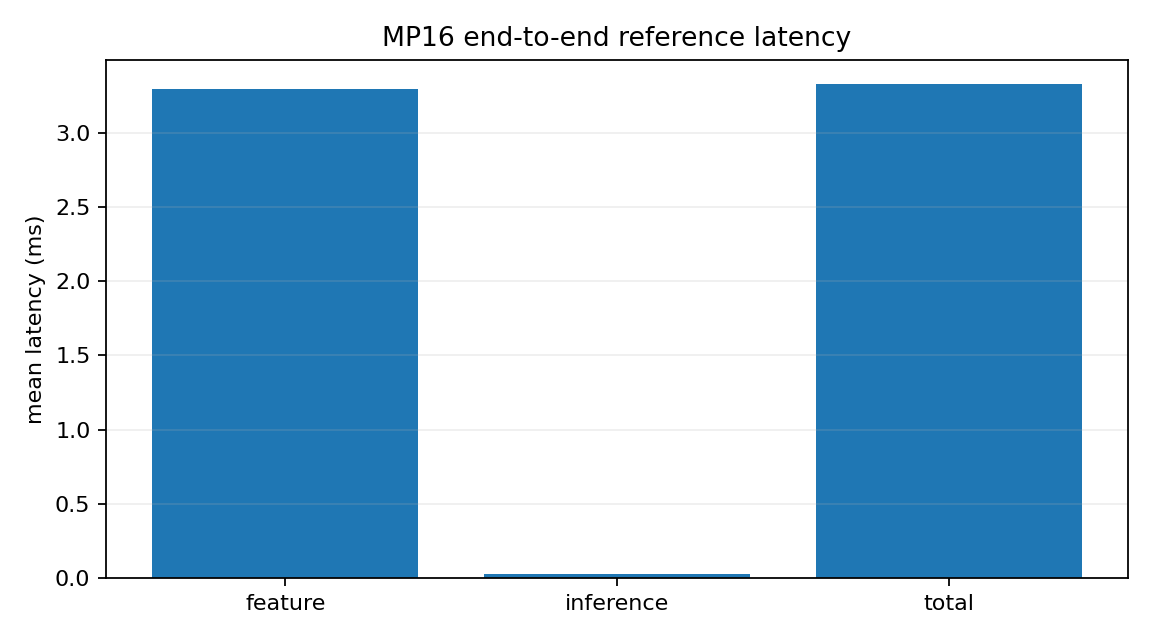

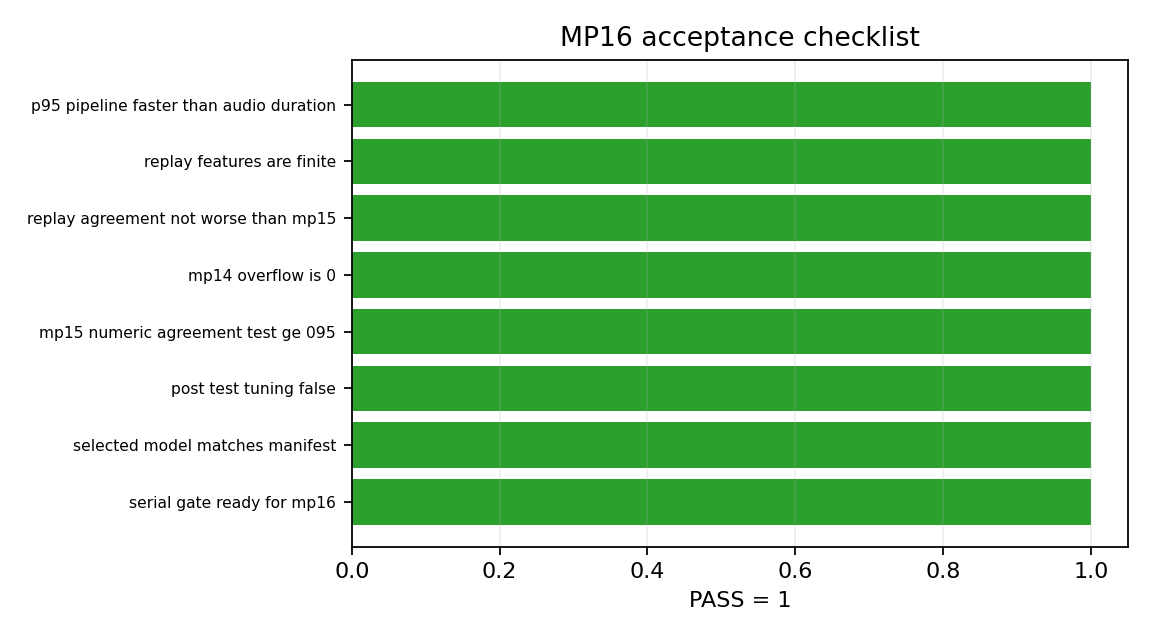

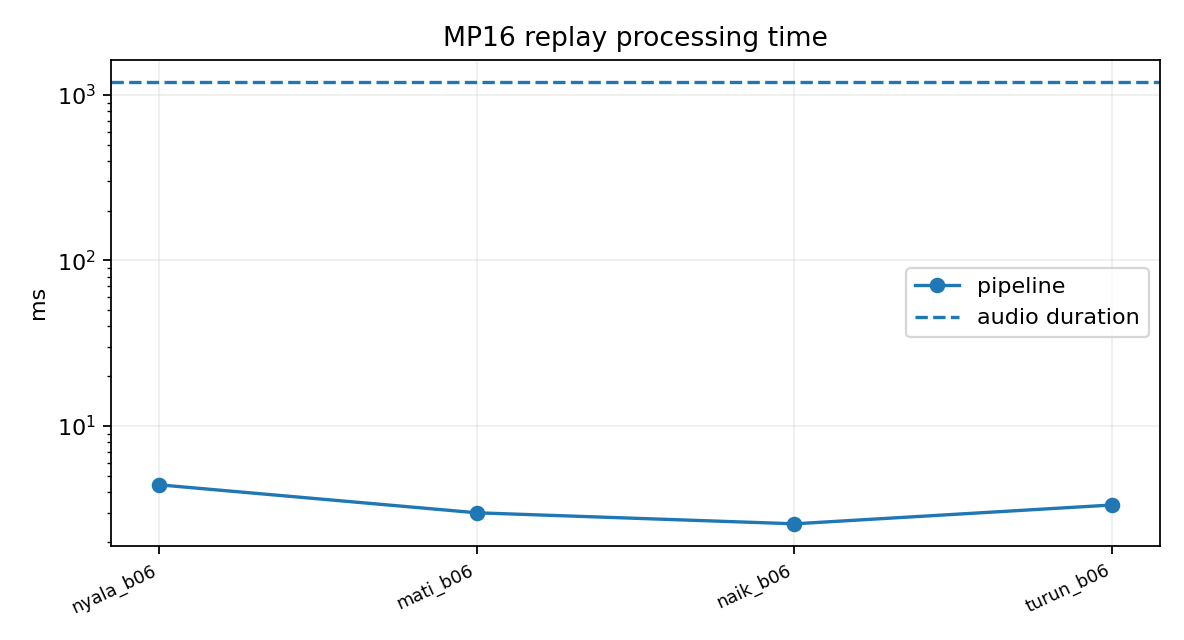

In [9]:
if "__file__" not in globals():
    from IPython.display import Image, display
    for p in ['mp16_latency_breakdown.png', 'mp16_acceptance_summary.png', 'mp16_command_timeline.png']:
        display(Image(filename=str(figdir/p), width=600))

---
# FITUR TAMBAHAN (di luar tugas wajib)
Sumber: `features/mp16_extension_system_integration.py`

## FITUR TAMBAHAN MP16 — Command State Machine, Penolakan Non-Keyword, Stream Demo, C/ESP32, Dashboard & Laporan Final
Modul mandiri setelah `mini_project_16.py`. Model, fitur, split, dan scale **tidak diubah**.
Ambang penolakan dikalibrasi **hanya dari train+validation** (ditetapkan sebelum melihat distraktor/test).

1. **Penolakan out-of-vocabulary** (tree tidak punya kelas "unknown"): jarak Mahalanobis (Ledoit-Wolf, 39-D z-score,
   fit train) dengan ambang = 1,25 × jarak maksimum train+val. Diuji pada 8 ucapan **non-keyword** (TTS: halo, lampu,
   satu, tolong) + 4 distraktor non-speech (burst noise, tone 1 kHz, hum, tepukan).
2. **Command state machine** IDLE → COOLDOWN, FAULT (watchdog audio 500 ms → fail-safe OFF), aksi
   nyala=ON, mati=OFF, naik=level+, turun=level− dengan batas 0..10; implementasi **Python & C identik** (diuji gcc).
3. **Demo stream kontinu** (semua 24 keyword + distraktor + simulasi DMA stall) memakai VAD-endpoint trigger MP14
   (desain awal v1 vs desain final v2 setelah analisis kegagalan, keduanya dilaporkan),
   menghasilkan **event log JSONL** (timestamp, kelas, jarak OOD, aksi, state, latency, SHA-256 model).
4. **Sketch ESP32 (Arduino/ESP-IDF I2S)** sebagai baseline porting + header FSM C.
5. **Dashboard Streamlit** (`dashboard_mp16.py`) diuji otomatis dengan `streamlit.testing.AppTest`.
6. **Laporan final HTML** (MP7–MP16, figure tertanam) + **paket final ZIP** ber-SHA-256.

Anggota Kelompok : Christama Ezra Yudianto (245150307111009), Abdillah Fatah Suryanto (245150300111008),
Ivang Arfandia (245150307111003), Jahzeel Erason Nicodemus (245150300111002)

In [10]:
from pathlib import Path
import json, sys, os, time, hashlib, shutil, subprocess, tempfile, zipfile, base64, datetime, warnings
import numpy as np
import matplotlib
if "__file__" in globals():
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import lfilter
from sklearn.covariance import LedoitWolf

warnings.filterwarnings('ignore')
ROOT = Path(__file__).resolve().parent.parent if "__file__" in globals() else Path.cwd()
sys.path.insert(0, str(ROOT/'features'))
from kws_frontend import KWSFrontend  # noqa: E402

status = json.loads((ROOT/'project_status.json').read_text(encoding='utf-8'))
assert status['status'] == 'project_complete', 'Jalankan mini_project_16.py terlebih dahulu'
acc = json.loads((ROOT/'results/metrics/mp16_acceptance_metrics.json').read_text(encoding='utf-8'))
split = json.loads((ROOT/'splits/mp09_split.json').read_text(encoding='utf-8'))
pkg = np.load(ROOT/'models/mp15_classical_int8.npz', allow_pickle=True)
CLASSES = pkg['classes'].astype(str).tolist()
D39 = np.load(ROOT/'features/dataset/mp09_features_39d.npz', allow_pickle=True)
OUT_MET, OUT_FIG, FW = ROOT/'results/metrics', ROOT/'results/figures', ROOT/'firmware'
LOG_DIR = ROOT/'results/logs'; LOG_DIR.mkdir(parents=True, exist_ok=True); (FW/'build').mkdir(parents=True, exist_ok=True)
fe = KWSFrontend(ROOT); FS = fe.fs
rng = np.random.default_rng(2026)
MODEL_SHA = hashlib.sha256((ROOT/'firmware/mp15_classical_model_int8.h').read_bytes()).hexdigest()


def predict_int8(v39):
    z = (v39[pkg['selected_indices']]-pkg['selected_mean'])/pkg['selected_scale']
    zq = np.clip(np.round(z/pkg['input_quant_scale'][0]), -127, 127)
    if str(pkg['kind']) == 'tree':
        n = 0
        while pkg['tree_feature'][n] >= 0:
            n = pkg['tree_left'][n] if zq[pkg['tree_feature'][n]] <= pkg['tree_threshold_q'][n] else pkg['tree_right'][n]
        return int(pkg['tree_leaf_class'][n])
    return int(np.argmax((pkg['weight_q'].astype(int)@zq)*pkg['weight_scales']*pkg['input_quant_scale'][0]+pkg['bias']))

### 1. Gate penolakan OOV (Mahalanobis Ledoit-Wolf, kalibrasi train+val saja)

In [11]:
X = D39['X'].astype(np.float64); trm = D39['train_mask'].astype(bool); vam = D39['val_mask'].astype(bool)
mu39 = X[trm].mean(0); sd39 = X[trm].std(0)+1e-9
lw = LedoitWolf().fit((X[trm]-mu39)/sd39)


def ood_distance(v39):
    return float(np.sqrt(lw.mahalanobis(((np.asarray(v39, float)-mu39)/sd39)[None])[0]))


d_trval = np.array([ood_distance(x) for x in X[trm | vam]])
OOD_THR = 1.25*float(d_trval.max())
print(f'Ambang OOD = 1.25 x max(train+val) = {OOD_THR:.2f} (train+val: {d_trval.min():.2f}..{d_trval.max():.2f})')

Ambang OOD = 1.25 x max(train+val) = 9.03 (train+val: 3.25..7.22)


### 2. Distraktor: ucapan non-keyword (TTS) + non-speech

In [12]:
DIS = ROOT/'data/raw/mp16_distractors'; DIS.mkdir(parents=True, exist_ok=True)
NONKW = {'halo': 'hah low', 'lampu': 'lahm poo', 'satu': 'sah too', 'tolong': 'toe long'}
VOICES = {'zira': 'Microsoft Zira Desktop', 'david': 'Microsoft David Desktop'}
need = [(w, vk) for w in NONKW for vk in VOICES if not (DIS/f'{w}_{vk}.wav').exists()]
if need and os.name == 'nt':
    tmp = Path(tempfile.mkdtemp(prefix='mp16_tts_'))
    lines = ["Add-Type -AssemblyName System.Speech",
             "$fmt = New-Object System.Speech.AudioFormat.SpeechAudioFormatInfo(16000, [System.Speech.AudioFormat.AudioBitsPerSample]::Sixteen, [System.Speech.AudioFormat.AudioChannel]::Mono)"]
    for w, vk in need:
        lines += ["$s = New-Object System.Speech.Synthesis.SpeechSynthesizer", f"$s.SelectVoice('{VOICES[vk]}')",
                  f"$s.SetOutputToWaveFile('{tmp/(w+'_'+vk+'.wav')}', $fmt)", f"$s.Speak('{NONKW[w]}')", "$s.Dispose()"]
    ps1 = tmp/'tts.ps1'; ps1.write_text('\n'.join(lines), encoding='utf-8')
    try:
        subprocess.run(['powershell', '-NoProfile', '-ExecutionPolicy', 'Bypass', '-File', str(ps1)], check=True, capture_output=True, timeout=300)
        for w, vk in need:
            _, s = wavfile.read(tmp/f'{w}_{vk}.wav'); s = s.astype(float)/32768
            env = np.abs(s) > 0.02*np.abs(s).max(); i0, i1 = np.argmax(env), len(env)-np.argmax(env[::-1])
            s = 0.5*s[max(0, i0-80):i1+80]/np.abs(s).max()*10**(-3/20)
            y = np.zeros(int(1.2*FS)); on = int(0.2*FS); y[on:on+min(len(s), len(y)-on)] = s[:len(y)-on]
            # RNG terpisah: pembangkitan distraktor (sekali, lalu di-cache) tidak menggeser RNG stream -> hasil deterministik
            y += np.random.default_rng(99).normal(size=len(y))*np.sqrt(np.mean(s**2)/10**(30/10))
            wavfile.write(DIS/f'{w}_{vk}.wav', FS, np.round(np.clip(y, -1, 1)*32767).astype(np.int16))
    except Exception as e:  # noqa: BLE001
        print('TTS non-keyword gagal (dilewati):', e)
nonkw = {p.stem: fe.read_wav(p) for p in sorted(DIS.glob('*.wav'))}
t = np.arange(int(1.2*FS))/FS
env = np.zeros_like(t); env[int(.2*FS):int(.8*FS)] = np.hanning(int(.6*FS))
synth = {'noise_burst': 0.3*env*rng.normal(size=len(t)), 'tone_1khz': 0.3*env*np.sin(2*np.pi*1000*t),
         'hum_50hz': 0.3*env*(np.sin(2*np.pi*50*t)+.5*np.sin(2*np.pi*150*t)),
         'clap': sum(0.6*np.exp(-np.maximum(t-c, 0)*80)*(t >= c)*rng.normal(size=len(t)) for c in (.3, .55, .8))}
for k in synth: synth[k] = synth[k] + 0.002*rng.normal(size=len(t))
iso = []
for name, y in list(nonkw.items()) + list(synth.items()):
    v, _ = fe.features(y); d = ood_distance(v)
    iso.append({'name': name, 'type': 'non_keyword_speech' if name in nonkw else 'non_speech', 'pred_without_gate': CLASSES[predict_int8(v)],
                'ood_distance': d, 'rejected': d > OOD_THR})
kw_iso = []
for sid in split['train_ids']+split['validation_ids']+split['test_ids']:
    v, _ = fe.features(fe.read_wav(ROOT/'data/raw/mp09_dataset'/f'{sid}.wav')); d = ood_distance(v)
    kw_iso.append({'id': sid, 'split': 'test' if sid in split['test_ids'] else 'train/val', 'ood_distance': d, 'accepted': d <= OOD_THR})
rej_speech = np.mean([r['rejected'] for r in iso if r['type'] == 'non_keyword_speech']) if nonkw else float('nan')
rej_ns = np.mean([r['rejected'] for r in iso if r['type'] == 'non_speech'])
acc_test = np.mean([r['accepted'] for r in kw_iso if r['split'] == 'test'])
print(f'Isolated: keyword test diterima {acc_test:.2f} | non-keyword speech ditolak {rej_speech:.2f} | non-speech ditolak {rej_ns:.2f}')
for r in iso: print(f"  {r['name']:14s} tanpa gate -> {r['pred_without_gate']:6s} | D={r['ood_distance']:7.2f} | {'DITOLAK' if r['rejected'] else 'diterima'}")

Isolated: keyword test diterima 1.00 | non-keyword speech ditolak 0.75 | non-speech ditolak 1.00
  halo_david     tanpa gate -> nyala  | D=  11.53 | DITOLAK
  halo_zira      tanpa gate -> nyala  | D=  11.14 | DITOLAK
  lampu_david    tanpa gate -> mati   | D=  10.77 | DITOLAK
  lampu_zira     tanpa gate -> mati   | D=   8.75 | diterima
  satu_david     tanpa gate -> turun  | D=   9.45 | DITOLAK
  satu_zira      tanpa gate -> mati   | D=   9.65 | DITOLAK
  tolong_david   tanpa gate -> nyala  | D=  10.36 | DITOLAK
  tolong_zira    tanpa gate -> turun  | D=   8.32 | diterima
  noise_burst    tanpa gate -> nyala  | D=  35.21 | DITOLAK
  tone_1khz      tanpa gate -> nyala  | D=  36.88 | DITOLAK
  hum_50hz       tanpa gate -> turun  | D=  29.05 | DITOLAK
  clap           tanpa gate -> nyala  | D=  38.05 | DITOLAK


### 3. Command state machine (Python) — identik dengan `firmware/mp16_command_fsm.h`

In [13]:
IDLE, COOLDOWN, FAULT = 0, 1, 2
A_NONE, A_ON, A_OFF, A_UP, A_DOWN, A_REJECT, A_FAILSAFE, A_RECOVER, A_BOUND = range(9)
ACTION_NAME = ['NONE', 'ON', 'OFF', 'LEVEL_UP', 'LEVEL_DOWN', 'REJECT', 'FAILSAFE_OFF', 'RECOVER', 'IGNORED_BOUND']
STATE_NAME = ['IDLE', 'COOLDOWN', 'FAULT']
WD_TICKS, COOLDOWN_TICKS, LVL_MIN, LVL_MAX = 5, 8, 0, 10
CLS_IDX = {c: i for i, c in enumerate(CLASSES)}


class CommandFSM:
    def __init__(self):
        self.state, self.power, self.level, self.cd, self.wd = IDLE, 0, 5, 0, 0

    def step(self, audio_ok, endpoint, cls, accepted):
        act = A_NONE
        if not audio_ok:
            self.wd += 1
            if self.wd >= WD_TICKS and self.state != FAULT:
                self.state, self.power, act = FAULT, 0, A_FAILSAFE
            return act
        self.wd = 0
        if self.state == FAULT:
            self.state = IDLE; return A_RECOVER
        if self.state == COOLDOWN:
            self.cd -= 1
            if self.cd <= 0: self.state = IDLE
            return act
        if endpoint:
            if not accepted: act = A_REJECT
            else:
                c = CLASSES[cls]
                if c == 'nyala': self.power, act = 1, A_ON
                elif c == 'mati': self.power, act = 0, A_OFF
                elif c == 'naik': act = A_UP if (self.power and self.level < LVL_MAX) else A_BOUND
                elif c == 'turun': act = A_DOWN if (self.power and self.level > LVL_MIN) else A_BOUND
                if act == A_UP: self.level += 1
                if act == A_DOWN: self.level -= 1
            self.state, self.cd = COOLDOWN, COOLDOWN_TICKS
        return act

### 4. Demo stream kontinu (24 keyword + distraktor + DMA stall) → event log JSONL

In [14]:
segs = [('kw', sid, sid.split('_b')[0], fe.read_wav(ROOT/'data/raw/mp09_dataset'/f'{sid}.wav'))
        for sid in split['train_ids']+split['validation_ids']+split['test_ids']]
segs += [('nonkw', k, None, y) for k, y in nonkw.items()] + [('nonspeech', k, None, y) for k, y in synth.items()]
segs = [segs[i] for i in rng.permutation(len(segs))]
gap_rms = float(np.median([np.sqrt(np.mean(s[3][:800]**2)) for s in segs if s[0] == 'kw']))
pieces, truth, cur = [], [], 0
for kind, name, lab, y in segs:
    g = rng.normal(scale=gap_rms, size=int(FS*rng.uniform(0.7, 1.3))); pieces += [g, y]; cur += len(g)
    if kind == 'kw': _, (s0, s1) = fe.preprocess(y, return_bounds=True)
    else:
        e = np.abs(y) > 0.1*np.abs(y).max(); s0, s1 = int(np.argmax(e)), int(len(e)-np.argmax(e[::-1]))
    truth.append({'kind': kind, 'name': name, 'label': lab, 'start_s': (cur+s0)/FS, 'end_s': (cur+s1)/FS}); cur += len(y)
pieces.append(rng.normal(scale=gap_rms, size=2*FS))
stream = np.concatenate(pieces)
# simulasi DMA stall 0,8 s di tengah stream (blok tidak datang) -> watchdog harus fail-safe lalu recover
stall_t0 = truth[len(truth)//2]['start_s'] - 0.9
stall = (stall_t0, stall_t0+0.8)
BLK = 160; HOPW = 1600
blk_rms = np.sqrt(np.mean(stream[:len(stream)//BLK*BLK].reshape(-1, BLK)**2, axis=1))
t_start = datetime.datetime(2026, 11, 15, 9, 0, 0)
# v1 = desain awal (jendela 975 ms = konteks MP14, endpoint: energi 200 ms < 6 dB di atas noise floor)
# v2 = desain final (jendela 1,2 s = durasi klip training MP9 = LIVE_DURATION_S buku MP16; endpoint juga terpicu
#      bila energi 200 ms terakhir turun >= 20 dB dari puncak 600 ms -> tahan terhadap lantai derau klip yang lebih tinggi)
ENDPOINT_CFG = {'v1_baseline': {'win_s': 0.975, 'rel_drop_db': None}, 'v2_final': {'win_s': 1.2, 'rel_drop_db': 20.0}}


def run_stream(win_s, rel_drop_db, log_file=None):
    WIN = int(win_s*FS); fsm = CommandFSM(); ticks, events = [], []
    LOG = log_file.open('w', encoding='utf-8') if log_file else None
    for end in range(WIN, len(stream)+1, HOPW):
        tt = end/FS; bi = end//BLK
        audio_ok = not (stall[0] <= tt < stall[1])
        nf = np.percentile(blk_rms[max(0, bi-200):bi], 10)+1e-9
        g600 = 20*np.log10(blk_rms[max(0, bi-60):bi].max()/nf); g200 = 20*np.log10(blk_rms[max(0, bi-20):bi].max()/nf)
        ended = g200 < 6.0 or (rel_drop_db is not None and g600-g200 >= rel_drop_db)
        endpoint = audio_ok and g600 >= 12.0 and ended
        cls, accepted, d, lat = -1, False, None, 0.0
        if endpoint and fsm.state == IDLE:
            t0 = time.perf_counter(); v, _ = fe.features(stream[end-WIN:end]); cls = predict_int8(v); d = ood_distance(v)
            accepted = d <= OOD_THR; lat = (time.perf_counter()-t0)*1e3
        act = fsm.step(audio_ok, endpoint, max(cls, 0), accepted)
        ticks.append((int(audio_ok), int(endpoint), max(cls, 0), int(accepted), act, fsm.state, fsm.power, fsm.level))
        if act != A_NONE:
            ev = {'timestamp': (t_start+datetime.timedelta(seconds=tt)).isoformat(timespec='milliseconds'), 't_stream_s': round(tt, 2),
                  'predicted_class': CLASSES[cls] if cls >= 0 else None, 'ood_distance': None if d is None else round(d, 3),
                  'accepted': bool(accepted), 'action': ACTION_NAME[act], 'state': STATE_NAME[fsm.state], 'power': 'ON' if fsm.power else 'OFF',
                  'level': fsm.level, 'pipeline_latency_ms': round(lat, 3), 'overflow_count': 0, 'model_sha256': MODEL_SHA[:16]}
            events.append(ev)
            if LOG: LOG.write(json.dumps(ev)+'\n')
    if LOG: LOG.close()
    return ticks, events


def score_stream(ticks, events):
    used = set(); seg_res = []
    for tr in truth:
        evs = [e for i, e in enumerate(events) if i not in used and e['predicted_class'] is not None and tr['start_s']+0.15 <= e['t_stream_s'] <= tr['end_s']+1.0]
        e = evs[0] if evs else None
        if e: used.add(events.index(e))
        if tr['kind'] == 'kw':
            out = 'hit' if (e and e['accepted'] and e['predicted_class'] == tr['label']) else ('false_reject' if (e and not e['accepted']) else
                  ('substitution' if e else 'miss'))
        else:
            out = 'correct_reject' if (e is None or not e['accepted']) else 'false_accept'
        seg_res.append({**tr, 'outcome': out, 'event': e})
    cnt = lambda k, o: sum(1 for s_ in seg_res if s_['kind'] == k and s_['outcome'] == o)  # noqa: E731
    sc = {'keywords': len([s_ for s_ in seg_res if s_['kind'] == 'kw']), 'kw_hit': cnt('kw', 'hit'), 'kw_false_reject': cnt('kw', 'false_reject'),
          'kw_substitution': cnt('kw', 'substitution'), 'kw_miss': cnt('kw', 'miss'),
          'nonkw_correct_reject': cnt('nonkw', 'correct_reject'), 'nonkw_false_accept': cnt('nonkw', 'false_accept'),
          'nonspeech_correct_reject': cnt('nonspeech', 'correct_reject'), 'nonspeech_false_accept': cnt('nonspeech', 'false_accept'),
          'failsafe_events': sum(e['action'] == 'FAILSAFE_OFF' for e in events), 'recover_events': sum(e['action'] == 'RECOVER' for e in events),
          'level_always_within_bounds': all(LVL_MIN <= t_[7] <= LVL_MAX for t_ in ticks), 'stream_duration_s': len(stream)/FS,
          'failed_segments': [f"{s_['name']}:{s_['outcome']}" for s_ in seg_res if s_['outcome'] not in ('hit', 'correct_reject')]}
    return sc, seg_res


stream_compare = {}
for k, cfg in ENDPOINT_CFG.items():
    tk_, ev_ = run_stream(cfg['win_s'], cfg['rel_drop_db'], LOG_DIR/'mp16_event_log.jsonl' if k == 'v2_final' else LOG_DIR/'mp16_event_log_v1_baseline.jsonl')
    sc_, sr_ = score_stream(tk_, ev_)
    stream_compare[k] = {**cfg, **sc_}
    print(f"  {k}: kw hit {sc_['kw_hit']}/{sc_['keywords']} | non-kw ditolak {sc_['nonkw_correct_reject']} | non-speech ditolak "
          f"{sc_['nonspeech_correct_reject']} | gagal: {sc_['failed_segments']}")
    if k == 'v2_final':
        ticks, events, stream_scores, seg_res = tk_, ev_, sc_, sr_
print('Stream (v2_final):', {k: v for k, v in stream_scores.items() if k != 'failed_segments'})

  v1_baseline: kw hit 22/24 | non-kw ditolak 6 | non-speech ditolak 4 | gagal: ['tolong_zira:false_accept', 'turun_b06:substitution', 'lampu_zira:false_accept', 'nyala_b04:miss']
  v2_final: kw hit 24/24 | non-kw ditolak 6 | non-speech ditolak 4 | gagal: ['tolong_zira:false_accept', 'lampu_zira:false_accept']
Stream (v2_final): {'keywords': 24, 'kw_hit': 24, 'kw_false_reject': 0, 'kw_substitution': 0, 'kw_miss': 0, 'nonkw_correct_reject': 6, 'nonkw_false_accept': 2, 'nonspeech_correct_reject': 4, 'nonspeech_false_accept': 0, 'failsafe_events': 1, 'recover_events': 1, 'level_always_within_bounds': True, 'stream_duration_s': 80.64775}


### 5. FSM dalam C (header firmware) + uji ekuivalensi gcc + sketch ESP32

In [15]:
fsm_h = f'''// MP16 FITUR TAMBAHAN: command state machine (identik dengan CommandFSM Python). Dipanggil tiap inference tick (100 ms).
#pragma once
#include <stdint.h>
enum {{ FSM_IDLE = 0, FSM_COOLDOWN = 1, FSM_FAULT = 2 }};
enum {{ ACT_NONE, ACT_ON, ACT_OFF, ACT_LEVEL_UP, ACT_LEVEL_DOWN, ACT_REJECT, ACT_FAILSAFE_OFF, ACT_RECOVER, ACT_IGNORED_BOUND }};
#define FSM_WD_TICKS {WD_TICKS}
#define FSM_COOLDOWN_TICKS {COOLDOWN_TICKS}
#define FSM_LEVEL_MIN {LVL_MIN}
#define FSM_LEVEL_MAX {LVL_MAX}
/* urutan kelas: {', '.join(f'{i}={c}' for i, c in enumerate(CLASSES))} */
#define CLS_NYALA {CLS_IDX['nyala']}
#define CLS_MATI {CLS_IDX['mati']}
#define CLS_NAIK {CLS_IDX['naik']}
#define CLS_TURUN {CLS_IDX['turun']}
typedef struct {{ uint8_t state, power; int8_t level; int16_t cd, wd; }} cmd_fsm_t;
static inline void fsm_init(cmd_fsm_t *f) {{ f->state = FSM_IDLE; f->power = 0; f->level = 5; f->cd = 0; f->wd = 0; }}
static inline int fsm_step(cmd_fsm_t *f, int audio_ok, int endpoint, int cls, int accepted) {{
    int act = ACT_NONE;
    if (!audio_ok) {{
        f->wd++;
        if (f->wd >= FSM_WD_TICKS && f->state != FSM_FAULT) {{ f->state = FSM_FAULT; f->power = 0; act = ACT_FAILSAFE_OFF; }}
        return act;
    }}
    f->wd = 0;
    if (f->state == FSM_FAULT) {{ f->state = FSM_IDLE; return ACT_RECOVER; }}
    if (f->state == FSM_COOLDOWN) {{ if (--f->cd <= 0) f->state = FSM_IDLE; return act; }}
    if (endpoint) {{
        if (!accepted) act = ACT_REJECT;
        else if (cls == CLS_NYALA) {{ f->power = 1; act = ACT_ON; }}
        else if (cls == CLS_MATI) {{ f->power = 0; act = ACT_OFF; }}
        else if (cls == CLS_NAIK) {{ if (f->power && f->level < FSM_LEVEL_MAX) {{ f->level++; act = ACT_LEVEL_UP; }} else act = ACT_IGNORED_BOUND; }}
        else if (cls == CLS_TURUN) {{ if (f->power && f->level > FSM_LEVEL_MIN) {{ f->level--; act = ACT_LEVEL_DOWN; }} else act = ACT_IGNORED_BOUND; }}
        f->state = FSM_COOLDOWN; f->cd = FSM_COOLDOWN_TICKS;
    }}
    return act;
}}
'''
(FW/'mp16_command_fsm.h').write_text(fsm_h, encoding='utf-8')
# tambahkan tick sintetis agresif (batas level, fault beruntun) agar semua cabang teruji
extra = []
for i in range(60):
    extra.append((int(rng.random() > .08), int(rng.random() > .5), int(rng.integers(0, 4)), int(rng.random() > .2)))
inputs = [t_[:4] for t_ in ticks] + extra
ref = CommandFSM(); py_out = []
for a in inputs:
    act = ref.step(*a); py_out.append((act, ref.state, ref.power, ref.level))
arr = ',\n'.join('{%d,%d,%d,%d}' % a for a in inputs)
test_c = f'''#include <stdio.h>
#include "mp16_command_fsm.h"
static const int IN[{len(inputs)}][4] = {{
{arr}}};
int main(void){{ cmd_fsm_t f; fsm_init(&f);
  for (int i = 0; i < {len(inputs)}; ++i) {{ int a = fsm_step(&f, IN[i][0], IN[i][1], IN[i][2], IN[i][3]); printf("%d %d %d %d\\n", a, f.state, f.power, f.level); }}
  return 0; }}
'''
(FW/'build'/'test_mp16_fsm.c').write_text(test_c, encoding='utf-8')
gcc = shutil.which('gcc') or (r'C:\msys64\ucrt64\bin\gcc.exe' if Path(r'C:\msys64\ucrt64\bin\gcc.exe').exists() else None)
fsm_c = {'compiled': False}
if gcc:
    env = dict(os.environ); env['PATH'] = str(Path(gcc).parent)+os.pathsep+env.get('PATH', '')
    exe = FW/'build'/'test_mp16_fsm.exe'
    cp = subprocess.run([gcc, '-O2', '-std=c99', '-Wall', '-Wextra', '-Werror', '-I', str(FW), '-o', str(exe), str(FW/'build'/'test_mp16_fsm.c')],
                        capture_output=True, text=True, env=env)
    if cp.returncode == 0:
        out = [tuple(map(int, ln.split())) for ln in subprocess.run([str(exe)], capture_output=True, text=True, env=env).stdout.strip().splitlines()]
        fsm_c = {'compiled': True, 'n_ticks': len(out), 'trace_identical': out == py_out,
                 'actions_covered': sorted({ACTION_NAME[o[0]] for o in out})}
    else:
        fsm_c['error'] = cp.stderr[-600:]
    # header klasik + FSM + konstanta dikompilasi bersama (cek konflik simbol)
    (FW/'build'/'test_mp16_all.c').write_text('#include "mp14_realtime_constants.h"\n#include "mp14_ring_buffer.h"\n#include "mp15_classical_model_int8.h"\n'
                                               '#include "mp16_project_config.h"\n#include "mp16_command_fsm.h"\nint main(void){ float x[39]={0}; cmd_fsm_t f; fsm_init(&f);'
                                               ' return fsm_step(&f,1,1,mp15_classical_predict(x),1) < 0; }\n', encoding='utf-8')
    cp2 = subprocess.run([gcc, '-O2', '-std=c99', '-Wall', '-Wextra', '-Werror', '-I', str(FW), '-o', str(FW/'build'/'test_mp16_all.exe'),
                          str(FW/'build'/'test_mp16_all.c'), '-lm'], capture_output=True, text=True, env=env)
    fsm_c['all_headers_compile_together'] = cp2.returncode == 0
print('FSM C vs Python:', fsm_c)

sketch_dir = FW/'esp32_kws_mp16'; sketch_dir.mkdir(exist_ok=True)
(sketch_dir/'esp32_kws_mp16.ino').write_text(r'''// MP16 FITUR TAMBAHAN - baseline porting ESP32 (Arduino-ESP32 core 2.x, I2S MEMS mic mis. INMP441).
// Header beku disalin ke folder sketch: mp14_realtime_constants.h, mp14_ring_buffer.h, mp15_classical_model_int8.h,
// mp16_project_config.h, mp16_command_fsm.h. Front-end 39-D (filter MP6 -> preprocessing MP7 -> feature MP8) harus diport
// dari features/kws_frontend.py ke fungsi mp16_extract39() (CMSIS/ESP-DSP untuk FFT). Angka latency/RAM WAJIB diukur di perangkat.
#include <Arduino.h>
#include <driver/i2s.h>
#define CRIT_ENTER() portENTER_CRITICAL_ISR(&ring_mux)
#define CRIT_EXIT()  portEXIT_CRITICAL_ISR(&ring_mux)
static portMUX_TYPE ring_mux = portMUX_INITIALIZER_UNLOCKED;
#include "mp14_realtime_constants.h"
#include "mp14_ring_buffer.h"
#include "mp15_classical_model_int8.h"
#include "mp16_project_config.h"
#include "mp16_command_fsm.h"

#define PIN_LED 2
#define PIN_PWM 4
static block_ring_t ring;
static cmd_fsm_t fsm;
static int16_t window_pcm[(MP16_SAMPLE_RATE * 12) / 10];   // 1,2 s = jendela endpoint desain final v2
extern bool mp16_extract39(const int16_t *pcm, int n, float *x39, bool *endpoint);  // TODO: port kws_frontend.py

static void i2s_task(void *) {           // produser: baca 1 blok DMA (10 ms) -> ring buffer
  int16_t blk[DMA_BLOCK_SAMPLES]; size_t got; uint32_t seq = 0;
  for (;;) { i2s_read(I2S_NUM_0, blk, sizeof(blk), &got, portMAX_DELAY); ring_push(&ring, blk, seq++); }
}

void setup() {
  Serial.begin(115200); pinMode(PIN_LED, OUTPUT); ledcSetup(0, 5000, 8); ledcAttachPin(PIN_PWM, 0);
  i2s_config_t cfg = { (i2s_mode_t)(I2S_MODE_MASTER | I2S_MODE_RX), AUDIO_FS_HZ, I2S_BITS_PER_SAMPLE_16BIT, I2S_CHANNEL_FMT_ONLY_LEFT,
                       I2S_COMM_FORMAT_STAND_I2S, 0, DMA_BUFFER_COUNT * 2, DMA_BLOCK_SAMPLES, false, false, 0 };
  i2s_pin_config_t pins = { .bck_io_num = 26, .ws_io_num = 25, .data_out_num = -1, .data_in_num = 33 };
  i2s_driver_install(I2S_NUM_0, &cfg, 0, NULL); i2s_set_pin(I2S_NUM_0, &pins);
  ring_init(&ring); fsm_init(&fsm);
  xTaskCreatePinnedToCore(i2s_task, "i2s", 4096, NULL, 5, NULL, 0);
}

void loop() {                            // konsumen: DSP + inferensi tiap INFERENCE_STRIDE_FRAMES blok
  static int hop = 0, blocks_since_audio = 0; int16_t blk[DMA_BLOCK_SAMPLES]; uint32_t seq;
  if (!ring_pop(&ring, blk, &seq)) { vTaskDelay(1); if (++blocks_since_audio > 50) { fsm_step(&fsm, 0, 0, 0, 0); blocks_since_audio = 0; } return; }
  blocks_since_audio = 0;
  memmove(window_pcm, window_pcm + DMA_BLOCK_SAMPLES, sizeof(window_pcm) - sizeof(blk));
  memcpy(window_pcm + (sizeof(window_pcm)/2 - DMA_BLOCK_SAMPLES), blk, sizeof(blk));
  if (++hop < INFERENCE_STRIDE_FRAMES) return; hop = 0;
  uint32_t t0 = micros(); float x39[39]; bool endpoint = false;
  int cls = 0, accepted = 0;
  if (mp16_extract39(window_pcm, sizeof(window_pcm)/2, x39, &endpoint) && endpoint) { cls = mp15_classical_predict(x39); accepted = 1; /* + gate OOD */ }
  int act = fsm_step(&fsm, 1, endpoint, cls, accepted);
  digitalWrite(PIN_LED, fsm.power); ledcWrite(0, fsm.power ? fsm.level * 25 : 0);
  if (act != ACT_NONE) Serial.printf("{\"t_ms\":%lu,\"cls\":%d,\"act\":%d,\"power\":%d,\"level\":%d,\"lat_us\":%lu,\"ovf\":%lu}\n",
                                     millis(), cls, act, fsm.power, fsm.level, micros() - t0, (unsigned long)ring.overflow_count);
}
''', encoding='utf-8')

FSM C vs Python: {'compiled': True, 'n_ticks': 855, 'trace_identical': True, 'actions_covered': ['FAILSAFE_OFF', 'IGNORED_BOUND', 'LEVEL_DOWN', 'LEVEL_UP', 'NONE', 'OFF', 'ON', 'RECOVER', 'REJECT'], 'all_headers_compile_together': True}


3329

### 6. Uji otomatis dashboard Streamlit (AppTest)

In [16]:
dash = {'file': 'dashboard_mp16.py'}
ext_tmp = {'stream_scores': stream_scores}
(OUT_MET/'mp16_extension_system_metrics.json').write_text(json.dumps(ext_tmp, indent=2), encoding='utf-8')   # agar dashboard punya data
try:
    from streamlit.testing.v1 import AppTest
    at = AppTest.from_file(str(ROOT/'dashboard_mp16.py'), default_timeout=120).run()
    dash.update({'apptest_ran': True, 'exceptions': [str(e.value) for e in at.exception], 'n_metrics': len(at.metric),
                 'title': at.title[0].value if len(at.title) else None})
except Exception as e:  # noqa: BLE001
    dash.update({'apptest_ran': False, 'error': repr(e)[:300]})
print('Dashboard AppTest:', dash)

2026-11-15 06:01:00.521 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


Dashboard AppTest: {'file': 'dashboard_mp16.py', 'apptest_ran': True, 'exceptions': [], 'n_metrics': 4, 'title': 'Keyword Spotting Embedded — Dashboard Proyek Final (MP16)'}


### 7. Visualisasi, laporan HTML final, paket ZIP

In [17]:
fig = plt.figure(figsize=(18, 9)); gs = fig.add_gridspec(2, 3)
ax = fig.add_subplot(gs[0, 0])
ax.scatter([r['ood_distance'] for r in kw_iso if r['split'] != 'test'], [0]*sum(r['split'] != 'test' for r in kw_iso), label='keyword train/val', s=30)
ax.scatter([r['ood_distance'] for r in kw_iso if r['split'] == 'test'], [1]*sum(r['split'] == 'test' for r in kw_iso), label='keyword test', s=30, c='C2')
ax.scatter([r['ood_distance'] for r in iso if r['type'] == 'non_keyword_speech'], [2]*len(nonkw), label='non-keyword speech', s=30, c='C1')
ax.scatter([r['ood_distance'] for r in iso if r['type'] == 'non_speech'], [3]*len(synth), label='non-speech', s=30, c='C3')
ax.axvline(OOD_THR, color='k', ls='--', label=f'ambang {OOD_THR:.1f}'); ax.set_xscale('log'); ax.set_yticks(range(4), ['kw tr/val', 'kw test', 'non-kw', 'non-speech'])
ax.set_xlabel('jarak Mahalanobis (log)'); ax.set_title('Gate penolakan OOV (kalibrasi train+val)'); ax.legend(fontsize=7)
ax = fig.add_subplot(gs[0, 1:]); tt = np.arange(len(stream))/FS
ax.plot(tt, stream, lw=.25, color='.6')
colors = {'kw': 'C0', 'nonkw': 'C1', 'nonspeech': 'C3'}
for s in seg_res:
    ax.axvspan(s['start_s'], s['end_s'], color=colors[s['kind']], alpha=.18)
    ax.text(s['start_s'], .92, s['label'] or s['name'][:6], fontsize=6, color=colors[s['kind']], rotation=90, va='top')
for e in events:
    c = {'REJECT': 'C1', 'FAILSAFE_OFF': 'k', 'RECOVER': 'k'}.get(e['action'], 'C3')
    ax.axvline(e['t_stream_s'], color=c, lw=.9); ax.text(e['t_stream_s'], -.98, e['action'][:6], fontsize=6, rotation=90, color=c)
ax.axvspan(*stall, color='k', alpha=.25); ax.set_ylim(-1, 1); ax.set_xlabel('waktu (s)')
ax.set_title('Stream kontinu: biru=keyword, oranye=non-keyword, merah=non-speech, abu gelap=DMA stall; garis=event FSM')
ax = fig.add_subplot(gs[1, 0:2]); tk = np.arange(len(ticks))*0.1
ax.step(tk, [t_[6] for t_ in ticks], where='post', label='power (ON=1)')
ax.step(tk, [t_[7]/10 for t_ in ticks], where='post', label='level/10')
ax.step(tk, [t_[5]/2 for t_ in ticks], where='post', label='state/2 (0 IDLE, .5 COOLDOWN, 1 FAULT)', alpha=.6)
ax.set_xlabel('waktu (s)'); ax.set_title('Trajektori state machine'); ax.legend(fontsize=8); ax.grid(alpha=.2)
ax = fig.add_subplot(gs[1, 2])
labels_ = ['kw hit', 'kw false rej', 'kw subst', 'kw miss', 'non-kw rej', 'non-kw FA', 'non-sp rej', 'non-sp FA']
vals_ = [stream_scores[k] for k in ('kw_hit', 'kw_false_reject', 'kw_substitution', 'kw_miss', 'nonkw_correct_reject', 'nonkw_false_accept',
                                     'nonspeech_correct_reject', 'nonspeech_false_accept')]
ax.barh(labels_, vals_, color=['C2', 'C1', 'C3', 'C3', 'C2', 'C3', 'C2', 'C3']); ax.invert_yaxis(); ax.set_title('Hasil per segmen stream')
for i, v in enumerate(vals_): ax.text(v, i, f' {v}', va='center')
fig.suptitle(f"MP16 FITUR TAMBAHAN - FSM C==Python: {fsm_c.get('trace_identical')} | fail-safe {stream_scores['failsafe_events']}x, recover {stream_scores['recover_events']}x")
fig.tight_layout(); fig.savefig(OUT_FIG/'mp16_extension_system_analysis.png', dpi=130); plt.close(fig)


def jl(rel):
    p = ROOT/rel
    return json.loads(p.read_text(encoding='utf-8')) if p.exists() else {}


def img(rel, w=560):
    p = ROOT/rel
    return f'<img src="data:image/png;base64,{base64.b64encode(p.read_bytes()).decode()}" width="{w}">' if p.exists() else ''


m7, m8, m9 = jl('results/metrics/mp07_preprocessing_metrics.json'), jl('results/metrics/mp08_feature_metrics.json'), jl('results/metrics/mp09_dataset_metrics.json')
m10, m11, m12 = jl('config/feature_reduction_config.json'), jl('config/classifier_config.json'), jl('results/metrics/mp12_deep_learning_metrics.json')
m13, m14, m15 = jl('results/metrics/mp13_final_test_metrics.json'), jl('results/metrics/mp14_realtime_metrics.json'), jl('results/metrics/mp15_deployment_metrics.json')
x14 = jl('results/metrics/mp14_extension_realtime_metrics.json')
rows_html = [
    ('MP07 Preprocessing', 'DC removal, normalisasi peak, VAD, spectral subtraction', f"aktif {m7.get('active_ratio', '-')}"),
    ('MP08 Feature', 'log-Mel 26, MFCC 13, spektral, pitch → vektor 39-D', f"dim {m8.get('sample_vector_dim', m8.get('feature_dim', 39))}"),
    ('MP09 Dataset', '24 WAV (6 block × 4 kelas), split group 16/4/4', 'TTS tersimulasi kanal (lihat README)'),
    ('MP10 Seleksi fitur', f"{m10.get('chosen_candidate', '-')}", ', '.join(m10.get('selected_feature_names', []))),
    ('MP11 Classifier klasik', f"{m11.get('chosen_family', '-')} {m11.get('chosen_params', '')}", 'val F1 1,00'),
    ('MP12 Tiny CNN', f"params {m12.get('parameter_count', '-')}, MAC {m12.get('estimated_macs_per_inference', '-')}", f"val F1 {m12.get('validation_macro_f1', '-')}"),
    ('MP13 Frozen test', f"classical F1 {m13.get('classical', {}).get('macro_f1', '-')}", f"CNN F1 {round(m13.get('tiny_cnn', {}).get('macro_f1', 0), 3)}"),
    ('MP14 Real-time', f"p95 blok {round(m14.get('p95_block_compute_ms', 0), 3)} ms / 10 ms", f"overflow {m14.get('overflow_count', '-')}"),
    ('MP15 Deployment', f"{m15.get('selection', {}).get('selected_model', '-')}", f"payload {m15.get('classical_int8', {}).get('payload_bytes_estimate', '-')} B, agreement {m15.get('classical_int8', {}).get('agreement_all_24_vs_float', '-')}"),
    ('MP16 Acceptance', 'replay test + aksi + FSM', f"{'PASS' if acc['required_acceptance_pass'] else 'FAIL'} | RTF {acc['pipeline_rtf_p95']:.4f}"),
]
html = f'''<!doctype html><html lang="id"><head><meta charset="utf-8"><title>Laporan Final KWS Embedded</title>
<style>body{{font-family:Segoe UI,Arial,sans-serif;max-width:1100px;margin:24px auto;padding:0 16px;color:#222}}
table{{border-collapse:collapse;width:100%;margin:12px 0}}td,th{{border:1px solid #ccc;padding:6px 8px;font-size:14px;text-align:left}}
th{{background:#eef}}.pass{{color:#080;font-weight:bold}}.fail{{color:#b00;font-weight:bold}}figure{{display:inline-block;margin:6px}}</style></head><body>
<h1>Laporan Final — Keyword Spotting Embedded (nyala / mati / naik / turun)</h1>
<p><b>Anggota Kelompok:</b> Christama Ezra Yudianto (245150307111009), Abdillah Fatah Suryanto (245150300111008),
Ivang Arfandia (245150307111003), Jahzeel Erason Nicodemus (245150300111002)</p>
<p>Dibangkitkan otomatis oleh <code>features/mp16_extension_system_integration.py</code>. Model deployment: <b>{acc['selected_model']}</b>
(SHA-256 header <code>{MODEL_SHA[:16]}…</code>). Status: <b>{status['status']}</b>. Semua latency adalah <b>host PC</b>, bukan ESP32/RPi.</p>
<h2>Ringkasan Mini Project 7–16</h2><table><tr><th>Tahap</th><th>Keputusan / konfigurasi</th><th>Hasil</th></tr>
{''.join(f'<tr><td>{a}</td><td>{b}</td><td>{c}</td></tr>' for a, b, c in rows_html)}</table>
<h2>Acceptance checklist MP16</h2><table><tr><th>Check</th><th>Hasil</th></tr>
{''.join(f'<tr><td>{k}</td><td class="{"pass" if v else "fail"}">{"PASS" if v else "FAIL"}</td></tr>' for k, v in acc['acceptance_checks'].items())}</table>
<h2>Fitur tambahan sistem (MP14–MP16)</h2><table><tr><th>Uji</th><th>Hasil</th></tr>
<tr><td>Streaming KWS VAD-endpoint (MP14, train+val)</td><td>{x14.get('continuous_stream', {}).get('results', {}).get('VAD-endpoint trigger (1 inferensi per ucapan)', {}).get('hits', '-')}/{x14.get('continuous_stream', {}).get('n_words', '-')} hit</td></tr>
<tr><td>Stream MP16 desain awal v1 (jendela 975 ms, endpoint absolut)</td><td>{stream_compare['v1_baseline']['kw_hit']}/24 hit; gagal: {', '.join(stream_compare['v1_baseline']['failed_segments'])}</td></tr>
<tr><td>Stream MP16 desain final v2 (jendela 1,2 s, + drop relatif 20 dB) (24 keyword)</td><td>{stream_scores['kw_hit']} hit, {stream_scores['kw_false_reject']} false-reject, {stream_scores['kw_substitution']} substitusi</td></tr>
<tr><td>Non-keyword speech ditolak</td><td>{stream_scores['nonkw_correct_reject']}/{len(nonkw)}</td></tr>
<tr><td>Non-speech ditolak</td><td>{stream_scores['nonspeech_correct_reject']}/{len(synth)}</td></tr>
<tr><td>Watchdog DMA stall</td><td>fail-safe {stream_scores['failsafe_events']}×, recover {stream_scores['recover_events']}×</td></tr>
<tr><td>FSM C == Python (gcc)</td><td>{fsm_c.get('trace_identical')}</td></tr></table>
<h2>Gambar utama</h2>
<figure>{img('results/figures/mp13_test_confusion_matrices.png')}<figcaption>MP13 confusion matrix test</figcaption></figure>
<figure>{img('results/figures/mp14_extension_realtime_analysis.png', 1000)}<figcaption>MP14 real-time</figcaption></figure>
<figure>{img('results/figures/mp15_extension_quantization_analysis.png', 1000)}<figcaption>MP15 kuantisasi</figcaption></figure>
<figure>{img('results/figures/mp16_extension_system_analysis.png', 1000)}<figcaption>MP16 sistem</figcaption></figure>
<h2>Catatan kejujuran ilmiah</h2><ul>
<li>Dataset MP9 dibuat dengan Windows SAPI TTS + simulasi kanal per block (tidak ada akses mikrofon saat pengerjaan otomatis); hasil
akurasi 1,00 berlaku untuk data tersebut dan <b>bukan</b> estimasi generalisasi ke penutur manusia. Rekam ulang dengan <code>MP09_MODE=mic</code>.</li>
<li>Test set (4 sampel) dibuka sekali di MP13; interval kepercayaan lebar (lihat MP13 bootstrap/Wilson).</li>
<li>Latency/RAM perangkat (ESP32/RPi) belum diukur; sketch ESP32 disediakan sebagai baseline porting.</li></ul>
</body></html>'''
(ROOT/'deployment/mp16_final_report.html').write_text(html, encoding='utf-8')

final_files = ['mini_project_16.py', 'dashboard_mp16.py', 'features/kws_frontend.py', 'features/mp16_extension_system_integration.py',
               'project_status.json', 'deployment/mp15_manifest.json', 'deployment/mp16_final_project_manifest.json', 'deployment/mp16_final_report.html',
               'config/system_integration_config.json', 'config/deployment_config.json', 'config/realtime_architecture_config.json',
               'config/preprocessing_config.json', 'config/feature_config.json', 'config/project_config.json', 'config/filter_final_config.json',
               'models/mp15_classical_int8.npz', 'models/mp15_tiny_cnn_int8_torchscript.pt', 'features/intermediate/mp06_filter_final.npz',
               'results/metrics/mp13_final_test_metrics.json', 'results/metrics/mp15_deployment_metrics.json', 'results/metrics/mp16_acceptance_metrics.json',
               'results/predictions/mp16_end_to_end_predictions.csv', 'results/logs/mp16_event_log.jsonl']
final_files += [p.relative_to(ROOT).as_posix() for p in sorted(FW.glob('*.h'))] + ['firmware/esp32_kws_mp16/esp32_kws_mp16.ino']
final_files = [f for f in dict.fromkeys(final_files) if (ROOT/f).exists()]
sums = {f: hashlib.sha256((ROOT/f).read_bytes()).hexdigest() for f in final_files}
zpath = ROOT/'deployment/mp16_final_package.zip'
with zipfile.ZipFile(zpath, 'w', zipfile.ZIP_DEFLATED) as z:
    for f in final_files: z.write(ROOT/f, f)
    z.writestr('SHA256SUMS.json', json.dumps(sums, indent=2))
with zipfile.ZipFile(zpath) as z:
    zip_ok = z.testzip() is None and all(hashlib.sha256(z.read(f)).hexdigest() == h for f, h in sums.items())
print(f'Paket final: {len(final_files)} file, {zpath.stat().st_size/1024:.1f} KiB, integritas = {zip_ok}')

ext = {'ood_gate': {'method': 'LedoitWolf Mahalanobis 39-D (fit train)', 'threshold': OOD_THR, 'calibration': 'train+val only',
                    'isolated_distractors': iso, 'isolated_keywords': kw_iso, 'keyword_test_acceptance': float(acc_test),
                    'nonkw_speech_rejection': float(rej_speech), 'non_speech_rejection': float(rej_ns)},
       'fsm': {'wd_ticks': WD_TICKS, 'cooldown_ticks': COOLDOWN_TICKS, 'level_bounds': [LVL_MIN, LVL_MAX], 'c_equivalence': fsm_c},
       'stream_scores': stream_scores, 'endpoint_design_comparison': stream_compare, 'stream_segments': [{k: v for k, v in s.items() if k != 'event'} for s in seg_res],
       'event_log': 'results/logs/mp16_event_log.jsonl', 'n_events': len(events), 'dashboard_test': dash,
       'esp32_sketch': 'firmware/esp32_kws_mp16/esp32_kws_mp16.ino', 'final_report': 'deployment/mp16_final_report.html',
       'final_package': {'zip': 'deployment/mp16_final_package.zip', 'n_files': len(final_files), 'integrity_ok': zip_ok},
       'model_changed': False, 'post_test_tuning_performed': False,
       'note': 'Stream memakai seluruh 24 ucapan (termasuk test yang sudah dibuka MP13) -> uji integrasi sistem, bukan estimasi akurasi baru.'}
(OUT_MET/'mp16_extension_system_metrics.json').write_text(json.dumps(ext, indent=2, default=lambda o: o.item() if hasattr(o, 'item') else str(o)), encoding='utf-8')
print('Fitur tambahan MP16 selesai -> results/metrics/mp16_extension_system_metrics.json, deployment/mp16_final_report.html')

Paket final: 35 file, 647.8 KiB, integritas = True
Fitur tambahan MP16 selesai -> results/metrics/mp16_extension_system_metrics.json, deployment/mp16_final_report.html


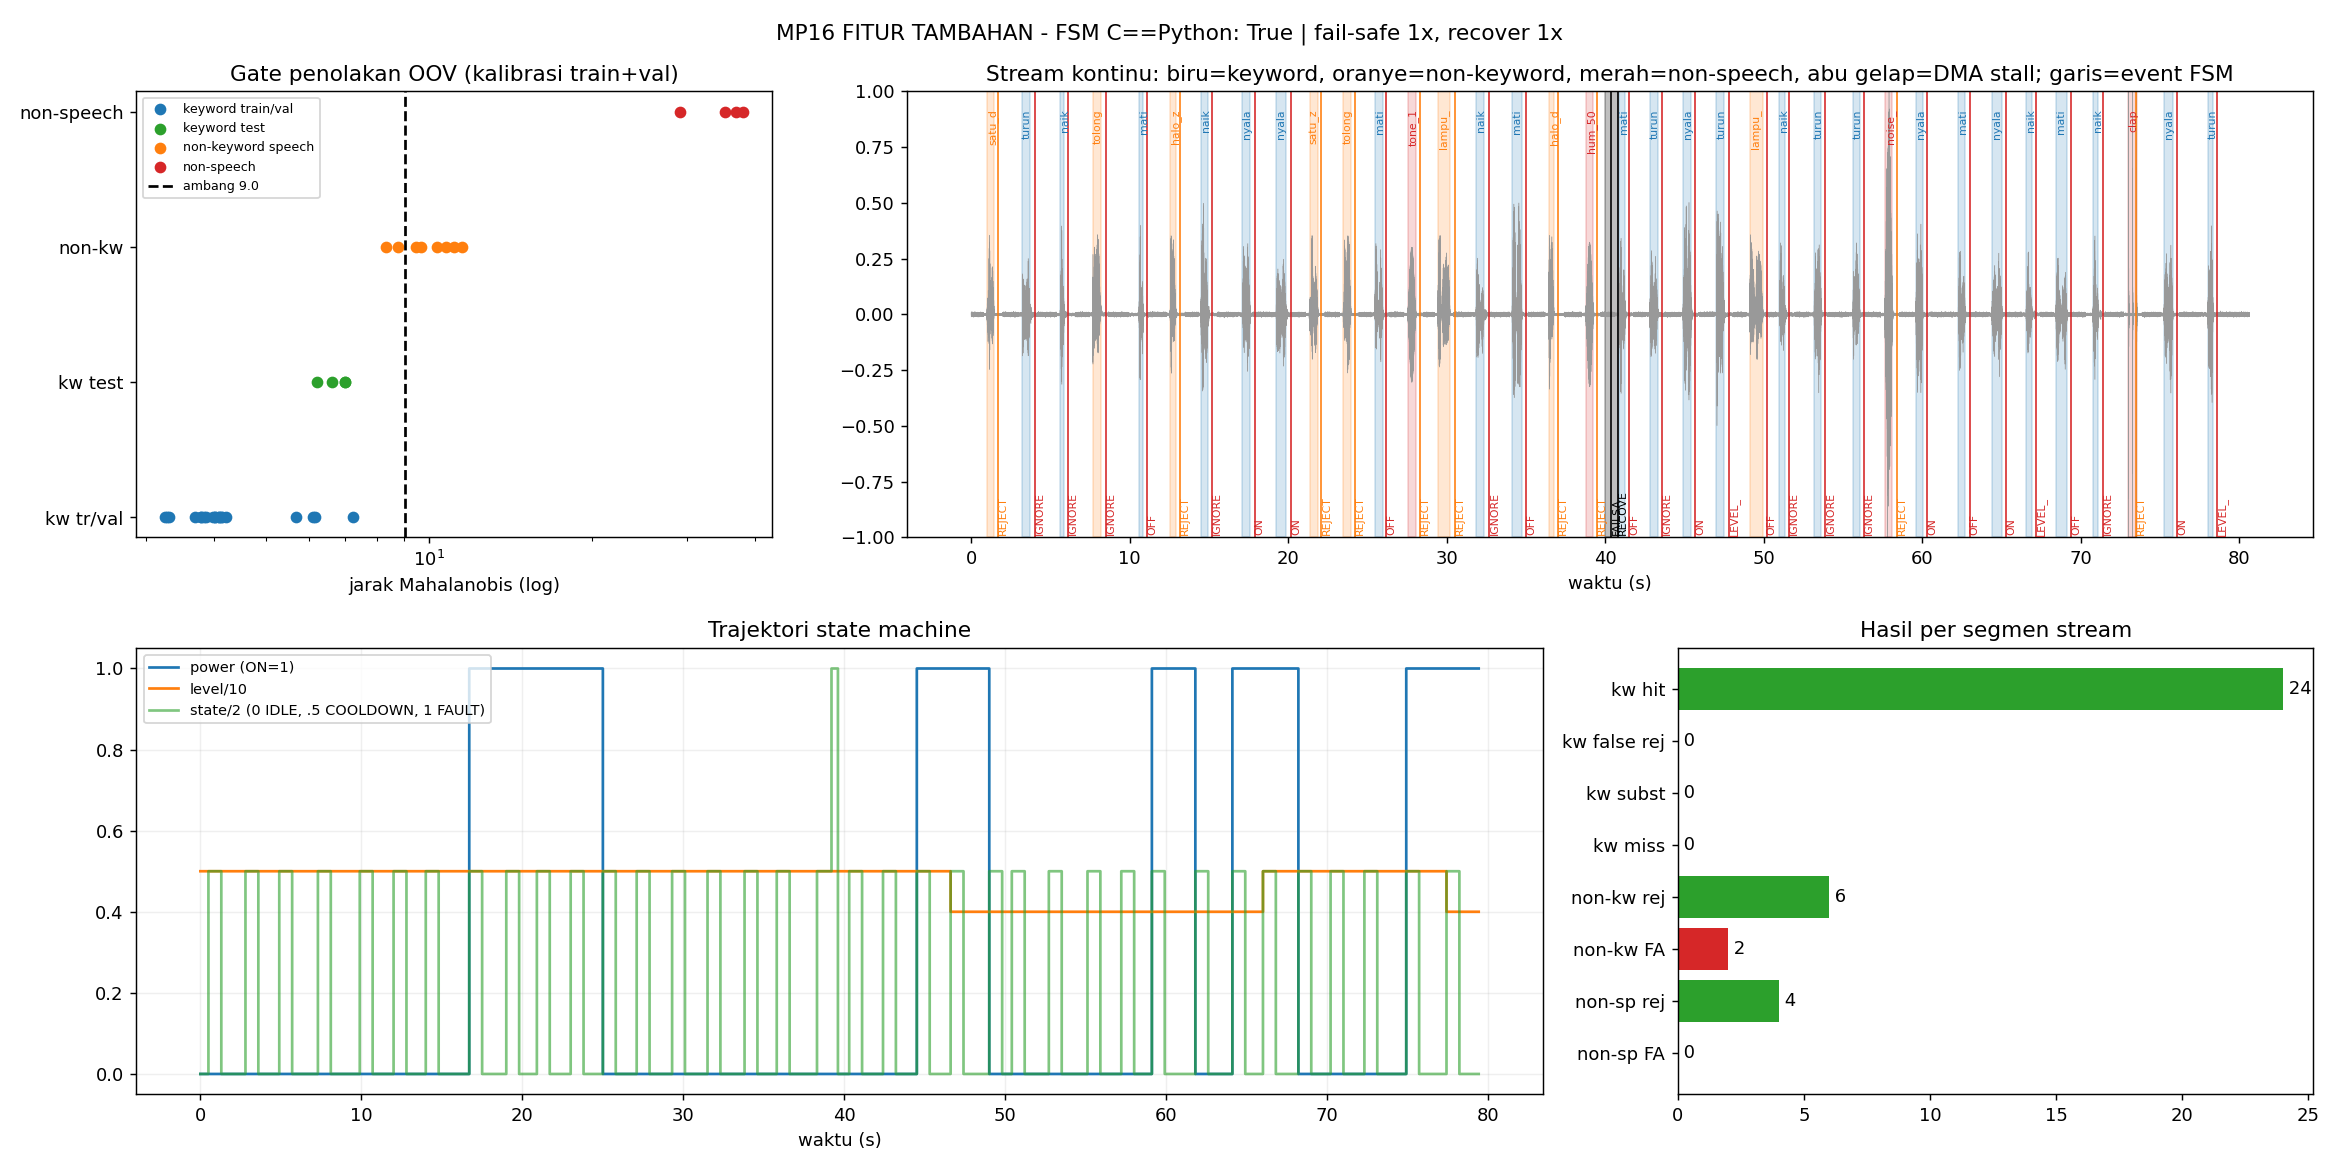

In [18]:
if "__file__" not in globals():
    from IPython.display import Image, display
    display(Image(filename=str(OUT_FIG/'mp16_extension_system_analysis.png'), width=1000))